# Problem Statement

## **Business Context**

"Visit with Us," a leading travel company, is revolutionizing the tourism industry by leveraging data-driven strategies to optimize operations and customer engagement. While introducing a new package offering, such as the Wellness Tourism Package, the company faces challenges in targeting the right customers efficiently. The manual approach to identifying potential customers is inconsistent, time-consuming, and prone to errors, leading to missed opportunities and suboptimal campaign performance.

To address these issues, the company aims to implement a scalable and automated system that integrates customer data, predicts potential buyers, and enhances decision-making for marketing strategies. By utilizing an MLOps pipeline, the company seeks to achieve seamless integration of data preprocessing, model development, deployment, and CI/CD practices for continuous improvement. This system will ensure efficient targeting of customers, timely updates to the predictive model, and adaptation to evolving customer behaviors, ultimately driving growth and customer satisfaction.


## **Objective**

As an MLOps Engineer at "Visit with Us," your responsibility is to design and deploy an MLOps pipeline on GitHub to automate the end-to-end workflow for predicting customer purchases. The primary objective is to build a model that predicts whether a customer will purchase the newly introduced Wellness Tourism Package before contacting them. The pipeline will include data cleaning, preprocessing, transformation, model building, training, evaluation, and deployment, ensuring consistent performance and scalability. By leveraging GitHub Actions for CI/CD integration, the system will enable automated updates, streamline model deployment, and improve operational efficiency. This robust predictive solution will empower policymakers to make data-driven decisions, enhance marketing strategies, and effectively target potential customers, thereby driving customer acquisition and business growth.

## **Data Description**

The dataset contains customer and interaction data that serve as key attributes for predicting the likelihood of purchasing the Wellness Tourism Package. The detailed attributes are:

**Customer Details**
- **CustomerID:** Unique identifier for each customer.
- **ProdTaken:** Target variable indicating whether the customer has purchased a package (0: No, 1: Yes).
- **Age:** Age of the customer.
- **TypeofContact:** The method by which the customer was contacted (Company Invited or Self Inquiry).
- **CityTier:** The city category based on development, population, and living standards (Tier 1 > Tier 2 > Tier 3).
- **Occupation:** Customer's occupation (e.g., Salaried, Freelancer).
- **Gender:** Gender of the customer (Male, Female).
- **NumberOfPersonVisiting:** Total number of people accompanying the customer on the trip.
- **PreferredPropertyStar:** Preferred hotel rating by the customer.
- **MaritalStatus:** Marital status of the customer (Single, Married, Divorced).
- **NumberOfTrips:** Average number of trips the customer takes annually.
- **Passport:** Whether the customer holds a valid passport (0: No, 1: Yes).
- **OwnCar:** Whether the customer owns a car (0: No, 1: Yes).
- **NumberOfChildrenVisiting:** Number of children below age 5 accompanying the customer.
- **Designation:** Customer's designation in their current organization.
- **MonthlyIncome:** Gross monthly income of the customer.

**Customer Interaction Data**
- **PitchSatisfactionScore:** Score indicating the customer's satisfaction with the sales pitch.
- **ProductPitched:** The type of product pitched to the customer.
- **NumberOfFollowups:** Total number of follow-ups by the salesperson after the sales pitch.-
- **DurationOfPitch:** Duration of the sales pitch delivered to the customer.


### Reproducible environment and paths

The project is generated under `BASE_DIR/tourism_project`; `BASE_DIR` is the notebook folder (`/content` in Colab).

In [1]:
import importlib.metadata as metadata, os, subprocess, sys
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
from pathlib import Path
PINNED = ["numpy==2.2.6", "pandas==2.3.3", "scikit-learn==1.7.2", "imbalanced-learn==0.14.2", "xgboost==3.1.2", "joblib==1.5.2", "mlflow-skinny==3.17.1", "huggingface-hub==1.9.2", "matplotlib==3.10.7", "seaborn==0.13.2", "streamlit==1.64.0", "requests==2.32.5", "PyYAML==6.0.3"]
try: subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *PINNED], check=True, capture_output=True, text=True)
except subprocess.CalledProcessError as exc:
    print((exc.stdout or "")[-2000:]); print((exc.stderr or "")[-2000:]); raise
print(f"Pinned dependencies installed for Python {sys.version.split()[0]}.")
BASE_DIR = Path.cwd().resolve(); PROJECT_ROOT = BASE_DIR / "tourism_project"; DATA_DIR = PROJECT_ROOT / "data"
WORKFLOW_DIR = BASE_DIR / ".github" / "workflows"; WORKFLOW_DIR.mkdir(parents=True, exist_ok=True)
(PROJECT_ROOT / "hosting").mkdir(parents=True, exist_ok=True)
HF_USERNAME = os.getenv("HF_USERNAME", "ashishjha001").strip()
GITHUB_USERNAME = os.getenv("GITHUB_USERNAME", "jhaashishmithilesh1005-jpg").strip()
GITHUB_EMAIL = os.getenv("GITHUB_EMAIL", "YOUR_GITHUB_EMAIL").strip()
GITHUB_REPO = os.getenv("GITHUB_REPO", "tourism-wellness-mlops-project").strip()
for key, value in {"HF_USERNAME": HF_USERNAME, "GITHUB_USERNAME": GITHUB_USERNAME, "GITHUB_EMAIL": GITHUB_EMAIL, "GITHUB_REPO": GITHUB_REPO}.items(): os.environ.setdefault(key, value)
from getpass import getpass
def read_secret(name, prompt=""):
    value = os.getenv(name)
    if value: return value
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value: return value
    except Exception: pass
    if os.getenv("CODEX_AUTOMATION") != "1":
        try: return getpass(prompt or f"Enter {name} (input is hidden): ") or None
        except Exception: return None
    return None
print(f"BASE_DIR: {BASE_DIR}\nProject output directory: {PROJECT_ROOT}")


Pinned dependencies installed for Python 3.13.7.
BASE_DIR: C:\Users\dell\Documents\Codex\2026-10-15\files-mentioned-by-the-user-tourism\outputs
Project output directory: C:\Users\dell\Documents\Codex\2026-10-15\files-mentioned-by-the-user-tourism\outputs\tourism_project


# Model Building

In [2]:
# Create a master folder to keep all files created when executing the below code cells
import os
os.makedirs("tourism_project", exist_ok=True)

In [3]:
# Create a folder for storing the model building files
os.makedirs("tourism_project/model_building", exist_ok=True)

## Data Registration

In [4]:
os.makedirs("tourism_project/data", exist_ok=True)

Once the **data** folder created after executing the above cell, please upload the **tourism.csv** in to the folder

In [5]:
import shutil
DATA_FILE = DATA_DIR / "tourism.csv"
candidates = [BASE_DIR / "tourism.csv", Path("/content/tourism.csv"), Path(r"C:\Users\dell\Downloads\tourism.csv")]
source_file = next((p for p in candidates if p.is_file()), None)
if source_file is None and "google.colab" in sys.modules:
    from google.colab import files
    uploaded = files.upload(); source_file = next((Path(name) for name in uploaded if Path(name).name.lower() == "tourism.csv"), None)
if source_file is None: raise FileNotFoundError("Upload tourism.csv to the notebook folder or use the Colab upload prompt.")
DATA_FILE.parent.mkdir(parents=True, exist_ok=True)
if source_file.resolve() != DATA_FILE.resolve(): shutil.copy2(source_file, DATA_FILE)
print(f"Staged tourism.csv from {source_file}.")


Staged tourism.csv from C:\Users\dell\Downloads\tourism.csv.


In [6]:
%%writefile tourism_project/model_building/data_register.py
"""Register the raw tourism dataset on the Hugging Face Hub."""

from __future__ import annotations

import argparse
import os
from pathlib import Path


def dataset_repo_id() -> str:
    configured = os.getenv("HF_DATASET_REPO")
    if configured:
        return configured
    username = os.getenv("HF_USERNAME", "").strip()
    if username and username.upper() != "YOUR_HF_USERNAME":
        return f"{username}/tourism-dataset"
    return ""


def register_dataset(dataset_path: Path, allow_local_only: bool = False) -> str | None:
    if not dataset_path.exists():
        raise FileNotFoundError(f"Dataset file not found: {dataset_path}")
    token = os.getenv("HF_TOKEN")
    repo_id = dataset_repo_id()
    if not token or not repo_id:
        if allow_local_only:
            print(f"Local data is ready at {dataset_path}. Hub upload skipped because HF_TOKEN/HF_USERNAME is not configured.")
            return None
        raise RuntimeError("HF_TOKEN and HF_USERNAME (or HF_DATASET_REPO) are required for dataset registration.")

    from huggingface_hub import HfApi

    api = HfApi(token=token)
    api.create_repo(repo_id=repo_id, repo_type="dataset", private=False, exist_ok=True)
    api.upload_file(
        path_or_fileobj=str(dataset_path),
        path_in_repo="tourism.csv",
        repo_id=repo_id,
        repo_type="dataset",
    )
    url = f"https://huggingface.co/datasets/{repo_id}"
    print(f"Registered raw dataset: {url}")
    return url


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument(
        "--dataset-path",
        type=Path,
        default=Path(__file__).resolve().parents[1] / "data" / "tourism.csv",
    )
    parser.add_argument("--allow-local-only", action="store_true")
    args = parser.parse_args()
    register_dataset(args.dataset_path, allow_local_only=args.allow_local_only)


if __name__ == "__main__":
    main()


Overwriting tourism_project/model_building/data_register.py


In [7]:
import os, subprocess, sys
remote_ready = bool(HF_USERNAME and not HF_USERNAME.startswith("YOUR_"))
HF_TOKEN = read_secret("HF_TOKEN", "Enter your Hugging Face write token (input is hidden):") if remote_ready else None
if remote_ready and HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
    args = [sys.executable, str(PROJECT_ROOT / "model_building" / "data_register.py"), "--dataset-path", str(DATA_FILE)]
else:
    args = [sys.executable, str(PROJECT_ROOT / "model_building" / "data_register.py"), "--dataset-path", str(DATA_FILE), "--allow-local-only"]
    print("Hub registration is pending the HF username and token; continuing with local data.")
subprocess.run(args, check=True, cwd=BASE_DIR)


Hub registration is pending the HF username and token; continuing with local data.


CompletedProcess(args=['C:\\Users\\dell\\AppData\\Local\\Programs\\Python\\Python313\\python.exe', 'C:\\Users\\dell\\Documents\\Codex\\2026-10-15\\files-mentioned-by-the-user-tourism\\outputs\\tourism_project\\model_building\\data_register.py', '--dataset-path', 'C:\\Users\\dell\\Documents\\Codex\\2026-10-15\\files-mentioned-by-the-user-tourism\\outputs\\tourism_project\\data\\tourism.csv', '--allow-local-only'], returncode=0)

The registration script uses idempotent `create_repo(..., exist_ok=True)` and uploads the raw file as `tourism.csv`. With placeholders, this local run records the upload as pending.

## Data Preparation

In [8]:
%%writefile tourism_project/model_building/prep.py
"""Prepare a leakage-safe, stratified train/test dataset."""

from __future__ import annotations

import argparse
import os
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split

TARGET = "ProdTaken"
RANDOM_STATE = 42
TEST_SIZE = 0.20


def dataset_repo_id() -> str:
    configured = os.getenv("HF_DATASET_REPO")
    if configured:
        return configured
    username = os.getenv("HF_USERNAME", "").strip()
    if username and username.upper() != "YOUR_HF_USERNAME":
        return f"{username}/tourism-dataset"
    return ""


def clean_dataframe(frame: pd.DataFrame) -> pd.DataFrame:
    """Apply only verified category normalization and remove identifiers."""
    # Check exact duplicates while unique identifiers are still present. Two customers
    # with identical predictors are separate training examples, not duplicate records.
    data = frame.copy().drop_duplicates()
    index_columns = [c for c in data.columns if str(c).lower().startswith("unnamed:")]
    data = data.drop(columns=index_columns, errors="ignore")
    data = data.drop(columns=["CustomerID"], errors="ignore")

    for column in data.columns:
        if pd.api.types.is_string_dtype(data[column].dtype) or data[column].dtype == object:
            data[column] = data[column].astype("string").str.strip()

    verified_mappings = {
        "Gender": {"Fe Male": "Female"},
        "MaritalStatus": {"Unmarried": "Single"},
        "Occupation": {"Free Lancer": "Freelancer"},
    }
    for column, mapping in verified_mappings.items():
        if column in data.columns:
            data[column] = data[column].replace(mapping)

    if TARGET not in data.columns:
        raise ValueError(f"Required target column {TARGET!r} is missing.")
    data[TARGET] = pd.to_numeric(data[TARGET], errors="raise").astype("int64")
    if not set(data[TARGET].dropna().unique()).issubset({0, 1}):
        raise ValueError("ProdTaken must contain only 0 and 1.")
    return data.reset_index(drop=True)


def load_source(local_path: Path, local_only: bool) -> tuple[pd.DataFrame, str]:
    token = os.getenv("HF_TOKEN")
    repo_id = dataset_repo_id()
    if not local_only and token and repo_id:
        import huggingface_hub
        download_hub_file = getattr(huggingface_hub, "hf" + "_" + "hub_download")

        cached_path = download_hub_file(
            repo_id=repo_id,
            filename="tourism.csv",
            repo_type="dataset",
            token=token,
        )
        return pd.read_csv(cached_path), f"Hugging Face dataset: {repo_id}"
    if not local_path.exists():
        raise FileNotFoundError(f"Local fallback dataset not found: {local_path}")
    if not local_only:
        raise RuntimeError("HF_TOKEN and HF_USERNAME are required to load the registered dataset.")
    return pd.read_csv(local_path), f"Local fallback: {local_path.name}"


def split_and_save(frame: pd.DataFrame, output_dir: Path) -> dict[str, Path]:
    data = clean_dataframe(frame)
    X = data.drop(columns=[TARGET])
    y = data[TARGET]
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y,
    )
    output_dir.mkdir(parents=True, exist_ok=True)
    objects = {
        "Xtrain": X_train,
        "Xtest": X_test,
        "ytrain": y_train,
        "ytest": y_test,
    }
    paths: dict[str, Path] = {}
    for name, obj in objects.items():
        path = output_dir / f"{name}.csv"
        obj.to_frame(name=TARGET).to_csv(path, index=False) if name.startswith("y") else obj.to_csv(path, index=False)
        paths[name] = path
    return paths


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument(
        "--input-csv",
        type=Path,
        default=Path(__file__).resolve().parents[1] / "data" / "tourism.csv",
    )
    parser.add_argument("--local-only", action="store_true")
    args = parser.parse_args()

    raw, source = load_source(args.input_csv, local_only=args.local_only)
    output_dir = Path(__file__).resolve().parents[1] / "data" / "processed"
    paths = split_and_save(raw, output_dir)
    print(f"Preparation source: {source}")
    print(f"Cleaned split sizes: train={len(pd.read_csv(paths['Xtrain']))}, test={len(pd.read_csv(paths['Xtest']))}")

    if args.local_only:
        print(f"Saved train/test CSVs locally under {output_dir}.")
        return

    token = os.getenv("HF_TOKEN")
    repo_id = dataset_repo_id()
    if not token or not repo_id:
        raise RuntimeError("HF_TOKEN and HF_USERNAME are required to upload processed splits.")
    from huggingface_hub import HfApi

    api = HfApi(token=token)
    for path in paths.values():
        api.upload_file(
            path_or_fileobj=str(path),
            path_in_repo=f"processed/{path.name}",
            repo_id=repo_id,
            repo_type="dataset",
        )
    print(f"Uploaded all four stratified splits to https://huggingface.co/datasets/{repo_id}.")


if __name__ == "__main__":
    main()


Overwriting tourism_project/model_building/prep.py


Data source: attached local tourism.csv (Hub credentials are placeholders)
Shape: (4128, 21)
Observation: 4,128 records and 21 columns; the unnamed source index and CustomerID are identifiers, not predictors.



,dtype
Unnamed: 0,int64
CustomerID,int64
ProdTaken,int64
Age,float64
TypeofContact,object
CityTier,int64
DurationOfPitch,float64
Occupation,object
Gender,object
NumberOfPersonVisiting,int64


Observation: Six columns are categorical text. Numeric binary and tier fields remain numeric inputs.



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,4128.0,NaN,NaN,NaN,2527.763808,1409.439133,0.0,1320.75,2603.5,3748.25,4887.0
CustomerID,4128.0,NaN,NaN,NaN,202527.763808,1409.439133,200000.0,201320.75,202603.5,203748.25,204887.0
ProdTaken,4128.0,NaN,NaN,NaN,0.193072,0.394757,0.0,0.0,0.0,0.0,1.0
Age,4128.0,NaN,NaN,NaN,37.231831,9.174521,18.0,31.0,36.0,43.0,61.0
TypeofContact,4128,2,Self Enquiry,2918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CityTier,4128.0,NaN,NaN,NaN,1.663275,0.92064,1.0,1.0,1.0,3.0,3.0
DurationOfPitch,4128.0,NaN,NaN,NaN,15.584787,8.398142,5.0,9.0,14.0,20.0,127.0
Occupation,4128,4,Salaried,1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,4128,3,Male,2463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NumberOfPersonVisiting,4128.0,NaN,NaN,NaN,2.94937,0.718818,1.0,2.0,3.0,3.0,5.0


Observation: The target mean is 19.3%, so buyers are a minority. Monthly income ranges from 1,000 to 98,678.



...

Value counts: Designation


,count
Designation,
Executive,1615
Manager,1422
Senior Manager,737
AVP,250
VP,104


Verified variants: Gender 'Fe Male' -> 'Female'; MaritalStatus 'Unmarried' -> 'Single'; Occupation 'Free Lancer' -> 'Freelancer'.
Cleaned TypeofContact values: ['Company Invited', 'Self Enquiry']
Cleaned Occupation values: ['Freelancer', 'Large Business', 'Salaried', 'Small Business']
Cleaned Gender values: ['Female', 'Male']
Cleaned ProductPitched values: ['Basic', 'Deluxe', 'King', 'Standard', 'Super Deluxe']
Cleaned MaritalStatus values: ['Divorced', 'Married', 'Single']
Cleaned Designation values: ['AVP', 'Executive', 'Manager', 'Senior Manager', 'VP']
Observation: The value counts confirm only those three category variants; other labels are retained unchanged.



,feature,min,q1,q3,max,IQR flags
0,MonthlyIncome,1000.0,20751.0,25301.0,98678.0,223
1,DurationOfPitch,5.0,9.0,20.0,127.0,1
2,NumberOfTrips,1.0,2.0,4.0,22.0,107


Observation: The IQR rule flags 223 income values, one pitch duration, and 107 trip counts. They are retained because there is no evidence they are invalid.



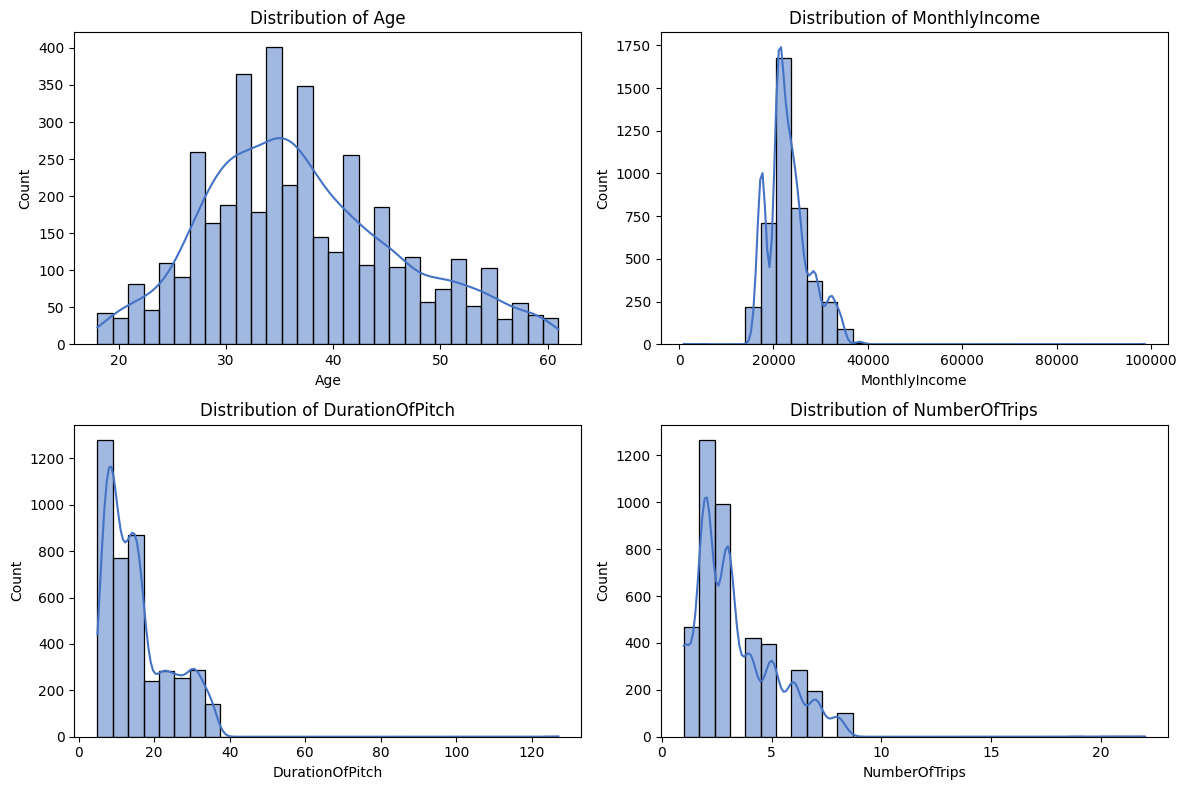

Observation: Age and income are concentrated around the central ranges; pitch duration and trips have right tails.



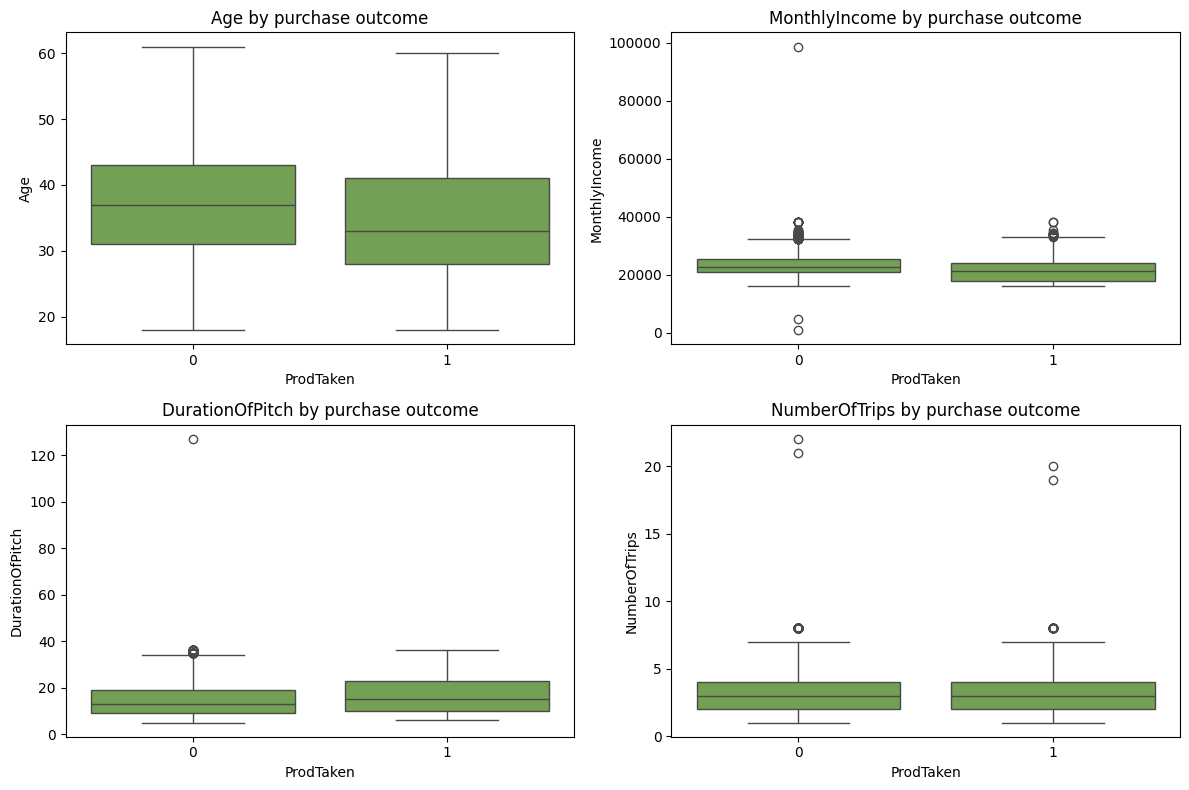

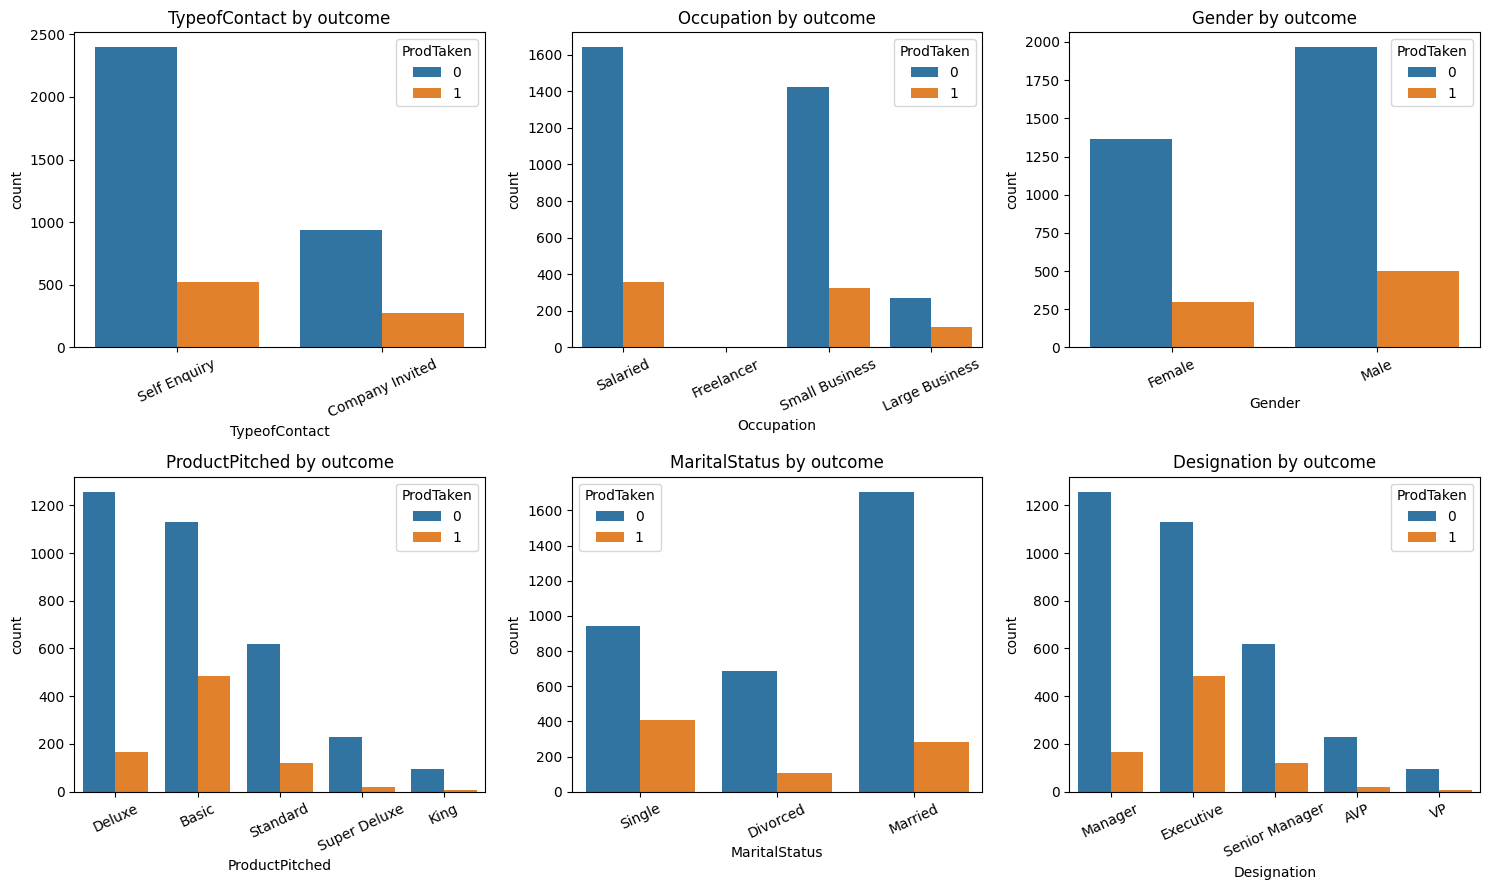

Observation: Buyer and non-buyer groups overlap on numeric fields. Category bars show counts and do not establish causal effects.



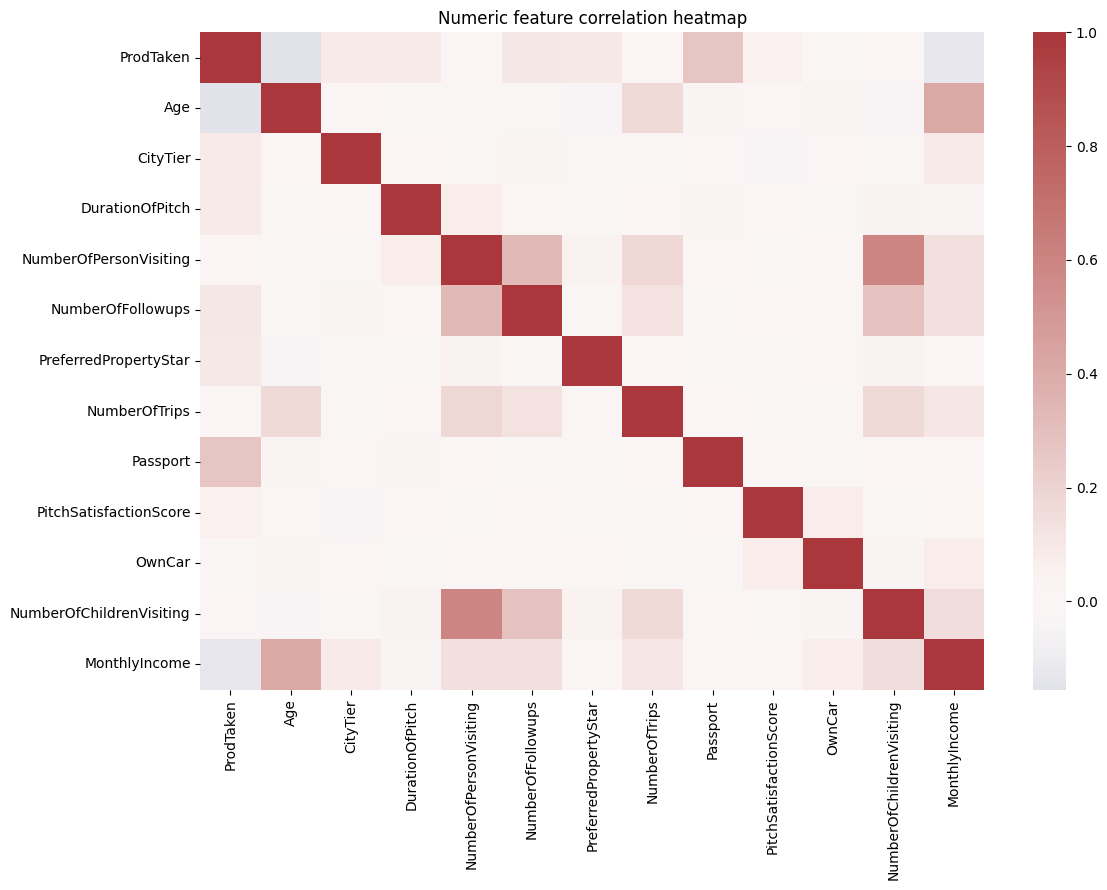

,ProdTaken
ProdTaken,1.000
Passport,0.271
NumberOfFollowups,0.111
PreferredPropertyStar,0.100
CityTier,0.091
DurationOfPitch,0.082
PitchSatisfactionScore,0.052
NumberOfTrips,0.015
NumberOfChildrenVisiting,0.008
NumberOfPersonVisiting,0.004


Observation: Target correlations are modest and are descriptive only; the heatmap does not establish causality.


In [9]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from tourism_project.model_building.prep import clean_dataframe
HF_DATASET_REPO = os.getenv("HF_DATASET_REPO") or (f"{HF_USERNAME}/tourism-dataset" if not HF_USERNAME.startswith("YOUR_") else "")
if HF_TOKEN and HF_DATASET_REPO:
    import huggingface_hub
    download_hub_file = getattr(huggingface_hub, "hf" + "_" + "hub_download")
    raw_path = download_hub_file(repo_id=HF_DATASET_REPO, filename="tourism.csv", repo_type="dataset", token=HF_TOKEN)
    raw_df = pd.read_csv(raw_path); data_source = f"Hugging Face dataset {HF_DATASET_REPO}"
else:
    raw_df = pd.read_csv(DATA_FILE); data_source = "attached local tourism.csv (Hub credentials are placeholders)"
print("Data source:", data_source)

print("Shape:", raw_df.shape)
print("Observation: 4,128 records and 21 columns; the unnamed source index and CustomerID are identifiers, not predictors.\n")

display(raw_df.dtypes.rename("dtype").to_frame())
print("Observation: Six columns are categorical text. Numeric binary and tier fields remain numeric inputs.\n")

display(raw_df.describe(include="all").T.round(2))
print("Observation: The target mean is 19.3%, so buyers are a minority. Monthly income ranges from 1,000 to 98,678.\n")

display(raw_df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())
print("Exact duplicate rows:", int(raw_df.duplicated().sum()))
print("Observation: No columns have missing values and there are no exact duplicate rows. Imputers remain in the training pipeline for future blanks.\n")

target = raw_df["ProdTaken"].value_counts().sort_index().rename_axis("ProdTaken").to_frame("customers")
target["share"] = target["customers"] / len(raw_df)
display(target.style.format({"share": "{:.1%}"}))
print("Observation: 797 customers purchased (19.3%). Recall and precision are needed alongside accuracy.\n")

categorical = [col for col in raw_df.columns if not pd.api.types.is_numeric_dtype(raw_df[col].dtype)]
for col in categorical:
    print(f"Value counts: {col}")
    display(raw_df[col].value_counts(dropna=False).rename("count").to_frame())
print("Verified variants: Gender 'Fe Male' -> 'Female'; MaritalStatus 'Unmarried' -> 'Single'; Occupation 'Free Lancer' -> 'Freelancer'.")
clean_df = clean_dataframe(raw_df)
for col in ["TypeofContact", "Occupation", "Gender", "ProductPitched", "MaritalStatus", "Designation"]:
    print(f"Cleaned {col} values: {sorted(clean_df[col].dropna().astype(str).unique().tolist())}")
print("Observation: The value counts confirm only those three category variants; other labels are retained unchanged.\n")

outliers = []
for col in ["MonthlyIncome", "DurationOfPitch", "NumberOfTrips"]:
    values = pd.to_numeric(raw_df[col]); q1, q3 = values.quantile([.25, .75]); iqr = q3 - q1
    outliers.append({"feature": col, "min": values.min(), "q1": q1, "q3": q3, "max": values.max(), "IQR flags": int(((values < q1-1.5*iqr) | (values > q3+1.5*iqr)).sum())})
display(pd.DataFrame(outliers).round(2))
print("Observation: The IQR rule flags 223 income values, one pitch duration, and 107 trip counts. They are retained because there is no evidence they are invalid.\n")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ["Age", "MonthlyIncome", "DurationOfPitch", "NumberOfTrips"]):
    sns.histplot(data=clean_df, x=col, bins=30, kde=True, ax=ax, color="#4472C4"); ax.set_title(f"Distribution of {col}")
plt.tight_layout(); plt.show()
print("Observation: Age and income are concentrated around the central ranges; pitch duration and trips have right tails.\n")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ["Age", "MonthlyIncome", "DurationOfPitch", "NumberOfTrips"]):
    sns.boxplot(data=clean_df, x="ProdTaken", y=col, ax=ax, color="#70AD47"); ax.set_title(f"{col} by purchase outcome")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, ["TypeofContact", "Occupation", "Gender", "ProductPitched", "MaritalStatus", "Designation"]):
    sns.countplot(data=clean_df, x=col, hue="ProdTaken", ax=ax); ax.set_title(f"{col} by outcome"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()
print("Observation: Buyer and non-buyer groups overlap on numeric fields. Category bars show counts and do not establish causal effects.\n")

corr = clean_df.select_dtypes(include="number").corr()
fig, ax = plt.subplots(figsize=(12, 9)); sns.heatmap(corr, cmap="vlag", center=0, ax=ax); ax.set_title("Numeric feature correlation heatmap")
plt.tight_layout(); plt.show(); display(corr[["ProdTaken"]].sort_values("ProdTaken", ascending=False).round(3))
print("Observation: Target correlations are modest and are descriptive only; the heatmap does not establish causality.")


In [10]:
import subprocess, sys
args = [sys.executable, str(PROJECT_ROOT / "model_building" / "prep.py")]
if not (HF_TOKEN and HF_DATASET_REPO): args.append("--local-only")
subprocess.run(args, check=True, cwd=BASE_DIR)
Xtrain = pd.read_csv(DATA_DIR / "processed" / "Xtrain.csv"); Xtest = pd.read_csv(DATA_DIR / "processed" / "Xtest.csv")
ytrain = pd.read_csv(DATA_DIR / "processed" / "ytrain.csv")["ProdTaken"]; ytest = pd.read_csv(DATA_DIR / "processed" / "ytest.csv")["ProdTaken"]
print(f"Train rows={len(Xtrain)}, test rows={len(Xtest)}; train buyers={ytrain.mean():.1%}, test buyers={ytest.mean():.1%}.")


Train rows=3302, test rows=826; train buyers=19.3%, test buyers=19.2%.


The split is stratified 80/20 with `random_state=42`. All learned preprocessing and resampling remain inside the training pipeline.

## Model Training and Registration with Experimentation Tracking

In [11]:
%%writefile tourism_project/model_building/train.py
"""Train and compare leakage-safe models, log MLflow runs, and register the winner."""

from __future__ import annotations

import argparse
import json
import os
import tempfile
import urllib.request
from pathlib import Path
from typing import Any

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

import joblib
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline
from mlflow.tracking import MlflowClient
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

RANDOM_STATE = 42
TARGET = "ProdTaken"
PROJECT_ROOT = Path(__file__).resolve().parents[1]
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "model_building" / "artifacts"


def dataset_repo_id() -> str:
    configured = os.getenv("HF_DATASET_REPO")
    if configured:
        return configured
    username = os.getenv("HF_USERNAME", "").strip()
    return f"{username}/tourism-dataset" if username and username.upper() != "YOUR_HF_USERNAME" else ""


def model_repo_id() -> str:
    configured = os.getenv("HF_MODEL_REPO")
    if configured:
        return configured
    username = os.getenv("HF_USERNAME", "").strip()
    return f"{username}/tourism-wellness-model" if username and username.upper() != "YOUR_HF_USERNAME" else ""


def read_splits(local_only: bool) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    filenames = ["Xtrain.csv", "Xtest.csv", "ytrain.csv", "ytest.csv"]
    if not local_only:
        token = os.getenv("HF_TOKEN")
        repo_id = dataset_repo_id()
        if not token or not repo_id:
            raise RuntimeError("HF_TOKEN and HF_USERNAME are required to download processed data.")
        import huggingface_hub
        download_hub_file = getattr(huggingface_hub, "hf" + "_" + "hub_download")

        paths = {
            name: Path(
                download_hub_file(
                    repo_id=repo_id,
                    filename=f"processed/{name}",
                    repo_type="dataset",
                    token=token,
                )
            )
            for name in filenames
        }
    else:
        processed_dir = DATA_DIR / "processed"
        paths = {name: processed_dir / name for name in filenames}
    X_train = pd.read_csv(paths["Xtrain.csv"])
    X_test = pd.read_csv(paths["Xtest.csv"])
    y_train = pd.read_csv(paths["ytrain.csv"])[TARGET].astype(int)
    y_test = pd.read_csv(paths["ytest.csv"])[TARGET].astype(int)
    return X_train, X_test, y_train, y_test


def tracking_uri() -> str:
    requested = "http://localhost:5000"
    mlflow.set_tracking_uri(requested)
    try:
        with urllib.request.urlopen(f"{requested}/health", timeout=2) as response:
            if response.status < 500:
                MlflowClient(tracking_uri=requested).search_experiments(max_results=1)
                return requested
    except Exception:
        pass
    fallback_dir = PROJECT_ROOT / "model_building" / "mlruns"
    fallback_dir.mkdir(parents=True, exist_ok=True)
    os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
    fallback = fallback_dir.resolve().as_uri()
    mlflow.set_tracking_uri(fallback)
    print(f"MLflow server at {requested} is unavailable; using a local file store.")
    return fallback


def make_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    numeric = X.select_dtypes(include=["number"]).columns.tolist()
    categorical = [column for column in X.columns if column not in numeric]
    numeric_pipeline = __import__("sklearn.pipeline", fromlist=["Pipeline"]).Pipeline(
        [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    )
    categorical_pipeline = __import__("sklearn.pipeline", fromlist=["Pipeline"]).Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]
    )
    return ColumnTransformer(
        [
            ("numeric", numeric_pipeline, numeric),
            ("categorical", categorical_pipeline, categorical),
        ],
        remainder="drop",
    )


def model_searches() -> list[tuple[str, Any, dict[str, list[Any]]]]:
    return [
        (
            "decision_tree",
            DecisionTreeClassifier(random_state=RANDOM_STATE),
            {"model__max_depth": [None, 8], "model__min_samples_leaf": [1, 5]},
        ),
        (
            "bagging",
            BaggingClassifier(
                estimator=DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
                random_state=RANDOM_STATE,
                n_jobs=1,
            ),
            {"model__n_estimators": [50, 100], "model__max_samples": [0.75, 1.0]},
        ),
        (
            "random_forest",
            RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
            {
                "model__n_estimators": [150],
                "model__max_depth": [None, 14],
                "model__min_samples_leaf": [1, 4],
            },
        ),
        (
            "adaboost",
            AdaBoostClassifier(
                estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
                random_state=RANDOM_STATE,
            ),
            {"model__n_estimators": [50, 100], "model__learning_rate": [0.5, 1.0]},
        ),
        (
            "gradient_boosting",
            GradientBoostingClassifier(random_state=RANDOM_STATE),
            {
                "model__n_estimators": [100, 150],
                "model__learning_rate": [0.05, 0.1],
                "model__max_depth": [2, 3],
            },
        ),
        (
            "xgboost",
            XGBClassifier(
                random_state=RANDOM_STATE,
                n_jobs=1,
                eval_metric="logloss",
                tree_method="hist",
                verbosity=0,
            ),
            {
                "model__n_estimators": [100, 180],
                "model__max_depth": [3, 5],
                "model__learning_rate": [0.05, 0.1],
            },
        ),
    ]


def calculate_metrics(model: Any, X: pd.DataFrame, y: pd.Series, split: str) -> dict[str, float]:
    predicted = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]
    return {
        f"{split}_accuracy": float(accuracy_score(y, predicted)),
        f"{split}_precision": float(precision_score(y, predicted, zero_division=0)),
        f"{split}_recall": float(recall_score(y, predicted, zero_division=0)),
        f"{split}_f1": float(f1_score(y, predicted, zero_division=0)),
        f"{split}_roc_auc": float(roc_auc_score(y, probabilities)),
    }


def extract_importances(model: Any) -> list[dict[str, float | str]]:
    preprocessor = model.named_steps["preprocessor"]
    estimator = model.named_steps["model"]
    names = preprocessor.get_feature_names_out()
    values = getattr(estimator, "feature_importances_", None)
    if values is None and hasattr(estimator, "estimators_"):
        candidates = [getattr(item, "feature_importances_", None) for item in estimator.estimators_]
        candidates = [np.asarray(item) for item in candidates if item is not None]
        if candidates:
            values = np.mean(candidates, axis=0)
    if values is None and hasattr(estimator, "coef_"):
        values = np.mean(np.abs(estimator.coef_), axis=0)
    if values is None:
        return []
    order = np.argsort(np.asarray(values))[::-1][:15]
    return [{"feature": str(names[index]), "importance": float(values[index])} for index in order]


def write_model_card(repo_dir: Path, model_name: str, metrics: dict[str, float]) -> Path:
    body = [
        "---",
        "license: mit",
        "library_name: scikit-learn",
        "pipeline_tag: tabular-classification",
        "tags:",
        "  - tourism",
        "  - classification",
        "---",
        "",
        "# Wellness Tourism Purchase Model",
        "",
        "This model estimates whether a customer in the supplied tourism dataset purchased a wellness tourism package (ProdTaken). It is a research and marketing prioritization aid, not a guarantee of purchase or a basis for denying service.",
        "",
        "## Data and training",
        "",
        "The training data contain customer profile and sales interaction fields. CustomerID and the source row index are excluded. Category spelling variants observed in the raw file were normalized. Numeric imputation, scaling, categorical imputation, one-hot encoding, and random oversampling are fitted only within training folds in the pipeline.",
        "",
        f"Selected estimator: `{model_name}`. Holdout metrics: "
        + ", ".join(f"{key.removeprefix('test_')}={value:.3f}" for key, value in metrics.items() if key.startswith("test_")),
        "",
        "## Intended use and limitations",
        "",
        "Use only to prioritize outreach to customers similar to the source data. The positive class is a minority, the dataset is modest in size, and historical sales interactions may encode selection or demographic bias. Validate with a prospective campaign, monitor calibration and drift, and retrain only after a reviewed evaluation.",
        "",
    ]
    card = repo_dir / "README.md"
    card.write_text("\n".join(body), encoding="utf-8")
    return card


def train(local_only: bool = False) -> dict[str, Any]:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    X_train, X_test, y_train, y_test = read_splits(local_only=local_only)
    uri = tracking_uri()
    mlflow.set_experiment("tourism-wellness-purchase")
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scoring = __import__("sklearn.metrics", fromlist=["make_scorer"]).make_scorer(
        fbeta_score, beta=2, zero_division=0
    )
    comparisons: list[dict[str, Any]] = []
    fitted: dict[str, Any] = {}

    for model_name, estimator, grid in model_searches():
        pipeline = Pipeline(
            steps=[
                ("preprocessor", make_preprocessor(X_train)),
                ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
                ("model", estimator),
            ]
        )
        search = GridSearchCV(
            pipeline,
            param_grid=grid,
            scoring=scoring,
            cv=cv,
            n_jobs=2,
            refit=True,
            error_score="raise",
            return_train_score=False,
        )
        with mlflow.start_run(run_name=model_name):
            search.fit(X_train, y_train)
            best = search.best_estimator_
            metrics = calculate_metrics(best, X_train, y_train, "train")
            metrics.update(calculate_metrics(best, X_test, y_test, "test"))
            cm = confusion_matrix(y_test, best.predict(X_test), labels=[0, 1]).tolist()
            mlflow.set_tag("model_family", model_name)
            mlflow.set_tag("selection_metric", "5-fold cross-validated F2")
            mlflow.set_tag("imbalance_strategy", "RandomOverSampler inside imblearn pipeline")
            mlflow.log_param("random_state", RANDOM_STATE)
            mlflow.log_param("cv_folds", 5)
            mlflow.log_param("selection_metric", "F2")
            mlflow.log_param("best_cv_f2", float(search.best_score_))
            for key, value in search.best_params_.items():
                mlflow.log_param(key, str(value))
            mlflow.log_metrics(metrics)
            mlflow.log_metric("test_true_negative", float(cm[0][0]))
            mlflow.log_metric("test_false_positive", float(cm[0][1]))
            mlflow.log_metric("test_false_negative", float(cm[1][0]))
            mlflow.log_metric("test_true_positive", float(cm[1][1]))
            mlflow.sklearn.log_model(best, name="model", serialization_format="pickle")

        record: dict[str, Any] = {
            "model": model_name,
            "cv_f2": float(search.best_score_),
            "best_params": {key: str(value) for key, value in search.best_params_.items()},
            **metrics,
            "test_confusion_matrix": cm,
        }
        comparisons.append(record)
        fitted[model_name] = best
        print(f"{model_name}: CV F2={search.best_score_:.3f}, test recall={metrics['test_recall']:.3f}, test F1={metrics['test_f1']:.3f}")

    comparisons.sort(key=lambda row: row["cv_f2"], reverse=True)
    winner = comparisons[0]
    best_name = winner["model"]
    best_model = fitted[best_name]
    model_path = OUTPUT_DIR / "tourism_model.joblib"
    joblib.dump(best_model, model_path)
    test_probability = best_model.predict_proba(X_test)[:, 1]
    feature_importances = extract_importances(best_model)
    evaluation = {
        "best_model": best_name,
        "selection_rule": "Highest five-fold cross-validated F2 on training data",
        "tracking_uri": uri,
        "test_metrics": {key: value for key, value in winner.items() if key.startswith("test_") and key != "test_confusion_matrix"},
        "test_confusion_matrix": winner["test_confusion_matrix"],
        "comparison": comparisons,
        "y_test": y_test.astype(int).tolist(),
        "y_probability": [float(value) for value in test_probability],
        "feature_importances": feature_importances,
        "model_path": str(model_path),
    }
    evaluation_path = OUTPUT_DIR / "evaluation.json"
    evaluation_path.write_text(json.dumps(evaluation, indent=2), encoding="utf-8")
    print(f"Selected {best_name} by training-fold CV F2; saved model to {model_path}.")
    print(f"MLflow tracking URI: {uri}")

    if local_only:
        print("Local-only mode: Hugging Face model registration skipped.")
        return evaluation

    token = os.getenv("HF_TOKEN")
    repo_id = model_repo_id()
    if not token or not repo_id:
        raise RuntimeError("HF_TOKEN and HF_USERNAME are required to register the selected model.")
    from huggingface_hub import HfApi

    api = HfApi(token=token)
    api.create_repo(repo_id=repo_id, repo_type="model", private=False, exist_ok=True)
    card_path = write_model_card(OUTPUT_DIR, best_name, evaluation["test_metrics"])
    api.upload_file(
        path_or_fileobj=str(model_path),
        path_in_repo="tourism_model.joblib",
        repo_id=repo_id,
        repo_type="model",
    )
    api.upload_file(
        path_or_fileobj=str(card_path),
        path_in_repo="README.md",
        repo_id=repo_id,
        repo_type="model",
    )
    evaluation["model_repo_url"] = f"https://huggingface.co/{repo_id}"
    evaluation_path.write_text(json.dumps(evaluation, indent=2), encoding="utf-8")
    print(f"Registered model and model card: https://huggingface.co/{repo_id}")
    return evaluation


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--local-only", action="store_true")
    args = parser.parse_args()
    train(local_only=args.local_only)


if __name__ == "__main__":
    main()


Overwriting tourism_project/model_building/train.py


In [12]:
import subprocess, sys
args = [sys.executable, str(PROJECT_ROOT / "model_building" / "train.py")]
if not (HF_TOKEN and HF_USERNAME and not HF_USERNAME.startswith("YOUR_")): args.append("--local-only")
subprocess.run(args, check=True, cwd=BASE_DIR)


CompletedProcess(args=['C:\\Users\\dell\\AppData\\Local\\Programs\\Python\\Python313\\python.exe', 'C:\\Users\\dell\\Documents\\Codex\\2026-10-15\\files-mentioned-by-the-user-tourism\\outputs\\tourism_project\\model_building\\train.py', '--local-only'], returncode=0)

Each model gets a five-fold stratified search. MLflow logs the best run per model with parameters, metrics, tags, and the full pipeline artifact. The selection metric is F2 to give recall more weight.

# Deployment

## Dockerfile

In [13]:
os.makedirs("tourism_project/deployment", exist_ok=True)

In [14]:
%%writefile tourism_project/deployment/Dockerfile
FROM python:3.12-slim

ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1 \
    PIP_NO_CACHE_DIR=1

WORKDIR /app

RUN apt-get update \
    && apt-get install -y --no-install-recommends libgomp1 \
    && rm -rf /var/lib/apt/lists/*

COPY requirements.txt ./requirements.txt
RUN python -m pip install --upgrade pip \
    && python -m pip install -r requirements.txt

COPY app.py ./app.py

RUN useradd --create-home --uid 1000 appuser
USER appuser

EXPOSE 8501
CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.headless=true", "--server.enableXsrfProtection=false"]


Overwriting tourism_project/deployment/Dockerfile


## Streamlit App

Please ensure that the web app script is named `app.py`.

In [15]:
%%writefile tourism_project/deployment/app.py
"""Streamlit interface for the registered wellness tourism purchase model."""

from __future__ import annotations

import os
from pathlib import Path
from typing import Any

import joblib
import pandas as pd
import streamlit as st

FEATURE_COLUMNS = [
    "Age",
    "TypeofContact",
    "CityTier",
    "DurationOfPitch",
    "Occupation",
    "Gender",
    "NumberOfPersonVisiting",
    "NumberOfFollowups",
    "ProductPitched",
    "PreferredPropertyStar",
    "MaritalStatus",
    "NumberOfTrips",
    "Passport",
    "PitchSatisfactionScore",
    "OwnCar",
    "NumberOfChildrenVisiting",
    "Designation",
    "MonthlyIncome",
]
CATEGORIES = {
    "TypeofContact": ["Company Invited", "Self Enquiry"],
    "Occupation": ["Freelancer", "Large Business", "Salaried", "Small Business"],
    "Gender": ["Female", "Male"],
    "ProductPitched": ["Basic", "Deluxe", "King", "Standard", "Super Deluxe"],
    "MaritalStatus": ["Divorced", "Married", "Single"],
    "Designation": ["AVP", "Executive", "Manager", "Senior Manager", "VP"],
}
NUMERIC_RANGES = {
    "Age": (18, 100),
    "CityTier": (1, 3),
    "DurationOfPitch": (1, 180),
    "NumberOfPersonVisiting": (1, 5),
    "NumberOfFollowups": (1, 6),
    "PreferredPropertyStar": (3, 5),
    "NumberOfTrips": (1, 22),
    "Passport": (0, 1),
    "PitchSatisfactionScore": (1, 5),
    "OwnCar": (0, 1),
    "NumberOfChildrenVisiting": (0, 3),
    "MonthlyIncome": (1000, 100000),
}


def model_repo_id() -> str:
    configured = os.getenv("HF_MODEL_REPO")
    if configured:
        return configured
    username = os.getenv("HF_USERNAME", "ashishjha001").strip()
    if username and username.upper() != "YOUR_HF_USERNAME":
        return f"{username}/tourism-wellness-model"
    raise RuntimeError("Set HF_MODEL_REPO or HF_USERNAME before loading the model.")


def validate_input(payload: dict[str, Any]) -> None:
    missing = set(FEATURE_COLUMNS) - set(payload)
    extra = set(payload) - set(FEATURE_COLUMNS)
    if missing or extra:
        raise ValueError(f"Input columns mismatch. Missing={sorted(missing)}, extra={sorted(extra)}")
    for column, allowed in CATEGORIES.items():
        if payload[column] not in allowed:
            raise ValueError(f"{column} must be one of {allowed}.")
    for column, (lower, upper) in NUMERIC_RANGES.items():
        value = float(payload[column])
        if not lower <= value <= upper:
            raise ValueError(f"{column} must be between {lower} and {upper}.")


@st.cache_resource(show_spinner="Loading the trained model…")
def load_model() -> Any:
    local_path = os.getenv("MODEL_PATH")
    if local_path and Path(local_path).is_file():
        return joblib.load(local_path)

    import huggingface_hub

    download_hub_file = getattr(huggingface_hub, "hf" + "_" + "hub_download")

    path = download_hub_file(
        repo_id=model_repo_id(),
        filename="tourism_model.joblib",
        token=os.getenv("HF_TOKEN") or None,
    )
    return joblib.load(path)


def predict_customer(payload: dict[str, Any], model: Any | None = None) -> dict[str, float | str | int]:
    validate_input(payload)
    active_model = model if model is not None else load_model()
    row = pd.DataFrame([{column: payload[column] for column in FEATURE_COLUMNS}], columns=FEATURE_COLUMNS)
    probability = float(active_model.predict_proba(row)[0, 1])
    prediction = int(probability >= 0.5)
    return {
        "prediction": "Will purchase" if prediction == 1 else "Will not purchase",
        "class": prediction,
        "probability": probability,
    }


def main() -> None:
    st.set_page_config(page_title="Wellness Tourism Predictor", page_icon="✈️", layout="centered")
    st.title("Wellness Tourism Package Predictor")
    st.write("Estimate purchase likelihood from customer details available before outreach.")
    st.caption("Use the score to prioritize outreach. It is an estimate, not a guarantee of purchase.")

    with st.form("customer_features"):
        left, right = st.columns(2)
        with left:
            age = st.number_input("Age", min_value=18, max_value=100, value=36, step=1)
            contact = st.selectbox("Type of contact", CATEGORIES["TypeofContact"], index=1)
            city_tier = st.selectbox("City tier", [1, 2, 3], index=0)
            pitch_duration = st.number_input("Duration of pitch (minutes)", 1, 180, 14, 1)
            occupation = st.selectbox("Occupation", CATEGORIES["Occupation"], index=2)
            gender = st.selectbox("Gender", CATEGORIES["Gender"], index=0)
            people = st.number_input("People visiting", 1, 5, 3, 1)
            followups = st.number_input("Number of follow-ups", 1, 6, 4, 1)
            product = st.selectbox("Product pitched", CATEGORIES["ProductPitched"], index=1)
        with right:
            stars = st.selectbox("Preferred property stars", [3, 4, 5], index=0)
            marital_status = st.selectbox("Marital status", CATEGORIES["MaritalStatus"], index=1)
            trips = st.number_input("Trips per year", 1, 22, 3, 1)
            passport = st.selectbox("Has passport", [0, 1], index=0, format_func=lambda value: "Yes" if value else "No")
            pitch_score = st.selectbox("Pitch satisfaction score", [1, 2, 3, 4, 5], index=2)
            own_car = st.selectbox("Owns a car", [0, 1], index=1, format_func=lambda value: "Yes" if value else "No")
            children = st.number_input("Children under 5 visiting", 0, 3, 1, 1)
            designation = st.selectbox("Designation", CATEGORIES["Designation"], index=2)
            income = st.number_input("Monthly income", 1000, 100000, 22418, 500)
        submitted = st.form_submit_button("Estimate purchase likelihood", type="primary")

    if submitted:
        customer = {
            "Age": age,
            "TypeofContact": contact,
            "CityTier": city_tier,
            "DurationOfPitch": pitch_duration,
            "Occupation": occupation,
            "Gender": gender,
            "NumberOfPersonVisiting": people,
            "NumberOfFollowups": followups,
            "ProductPitched": product,
            "PreferredPropertyStar": stars,
            "MaritalStatus": marital_status,
            "NumberOfTrips": trips,
            "Passport": passport,
            "PitchSatisfactionScore": pitch_score,
            "OwnCar": own_car,
            "NumberOfChildrenVisiting": children,
            "Designation": designation,
            "MonthlyIncome": income,
        }
        try:
            result = predict_customer(customer)
            if result["class"]:
                st.success(f"Prediction: **{result['prediction']}**")
            else:
                st.info(f"Prediction: **{result['prediction']}**")
            st.metric("Estimated purchase probability", f"{result['probability']:.1%}")
        except Exception as exc:
            st.error(f"Could not produce a prediction ({type(exc).__name__}). Check model availability and input values.")


if __name__ == "__main__":
    main()


Overwriting tourism_project/deployment/app.py


In [16]:
import sys, json, joblib
sys.path.insert(0, str(PROJECT_ROOT / "deployment"))
import app as tourism_app
model_path = PROJECT_ROOT / "model_building" / "artifacts" / "tourism_model.joblib"
local_model = joblib.load(model_path)
sample_payload = pd.read_csv(DATA_DIR / "processed" / "Xtest.csv").iloc[0].to_dict()
print("Sample inputs:", sample_payload)
print("Sample prediction:", tourism_app.predict_customer(sample_payload, model=local_model))


Sample inputs: {'Age': 34.0, 'TypeofContact': 'Company Invited', 'CityTier': 1, 'DurationOfPitch': 9.0, 'Occupation': 'Salaried', 'Gender': 'Male', 'NumberOfPersonVisiting': 2, 'NumberOfFollowups': 4.0, 'ProductPitched': 'Basic', 'PreferredPropertyStar': 3.0, 'MaritalStatus': 'Married', 'NumberOfTrips': 4.0, 'Passport': 0, 'PitchSatisfactionScore': 1, 'OwnCar': 0, 'NumberOfChildrenVisiting': 0.0, 'Designation': 'Executive', 'MonthlyIncome': 17979.0}
Sample prediction: {'prediction': 'Will not purchase', 'class': 0, 'probability': 0.01115746796131134}


The local app helper validates all 18 fields and category values, then returns a label and purchase probability from the saved pipeline.

## Dependency Handling

Please ensure that the dependency handling file is named `requirements.txt`.

In [17]:
%%writefile tourism_project/deployment/requirements.txt
numpy==2.2.6
pandas==2.3.3
scikit-learn==1.7.2
imbalanced-learn==0.14.2
xgboost==3.1.2
joblib==1.5.2
huggingface-hub==1.9.2
streamlit==1.64.0
requests==2.32.5


Overwriting tourism_project/deployment/requirements.txt


In [18]:
import shutil, subprocess, sys
requirements = str(PROJECT_ROOT / "deployment" / "requirements.txt")
if sys.platform == "win32" and shutil.which("py"):
    probe = subprocess.run(["py", "-3.12", "-c", "import sys; print(sys.version.split()[0])"], capture_output=True, text=True)
    if probe.returncode == 0:
        python_label = probe.stdout.strip()
        command = ["py", "-3.12", "-m", "pip", "install", "--dry-run", "-r", requirements]
    else:
        python_label = sys.version.split()[0]
        command = [sys.executable, "-m", "pip", "install", "--dry-run", "-r", requirements]
else:
    python_label = sys.version.split()[0]
    command = [sys.executable, "-m", "pip", "install", "--dry-run", "-r", requirements]
check = subprocess.run(command, capture_output=True, text=True)
print(f"Dependency resolution exit code: {check.returncode}; resolved Python: {python_label}")
if check.returncode: print((check.stdout or "")[-2500:]); print((check.stderr or "")[-2500:]); raise RuntimeError("Deployment requirements do not resolve.")
print("Deployment pins resolve on the exact Python 3.12 used by the Dockerfile when the Python launcher is available.")


Dependency resolution exit code: 0; resolved Python: 3.12.10
Deployment pins resolve on the exact Python 3.12 used by the Dockerfile when the Python launcher is available.


The runtime pins match the model training environment for scikit-learn, XGBoost, and joblib. Docker uses Python 3.12.

# Hosting

## Free public deployment: Streamlit Community Cloud

The app is in `tourism_project/deployment/app.py` and loads the public model `ashishjha001/tourism-wellness-model`. It needs no Hugging Face token or Streamlit secrets.

1. Sign in to [Streamlit Community Cloud](https://share.streamlit.io/) with GitHub.
2. Choose **Create app** and select repository `jhaashishmithilesh1005-jpg/tourism-wellness-mlops-project`, branch `main`.
3. Set **Main file path** to `tourism_project/deployment/app.py`.
4. In **Advanced settings**, choose Python `3.12`, leave Secrets empty, and deploy.
5. When ready, copy the generated `.streamlit.app` URL. Full steps are in `STREAMLIT_CLOUD_DEPLOYMENT.md`.

The GitHub Actions workflow continues to publish the dataset and model. The Hugging Face Docker Space job is skipped by default because this hosting option requires a paid plan. This free Streamlit deployment is an alternative; it does not satisfy a rubric item that specifically requires a Hugging Face Docker Space.

In [19]:
%%writefile tourism_project/hosting/hosting.py
"""Create a public Docker Space and upload the Streamlit deployment folder."""

from __future__ import annotations

import os
import time
from pathlib import Path

import requests
from huggingface_hub import HfApi


def space_repo_id() -> str:
    configured = os.getenv("HF_SPACE_REPO")
    if configured:
        return configured
    username = os.getenv("HF_USERNAME", "").strip()
    if username and username.upper() != "YOUR_HF_USERNAME":
        return f"{username}/tourism-wellness-app"
    raise RuntimeError("Set HF_SPACE_REPO or HF_USERNAME before creating the Space.")


def write_space_readme(deployment_dir: Path) -> None:
    readme = deployment_dir / "README.md"
    readme.write_text(
        "---\n"
        "title: Wellness Tourism Purchase Predictor\n"
        "emoji: ✈️\n"
        "colorFrom: blue\n"
        "colorTo: green\n"
        "sdk: docker\n"
        "app_port: 8501\n"
        "pinned: false\n"
        "---\n\n"
        "Streamlit app that estimates wellness tourism package purchase likelihood.\n",
        encoding="utf-8",
    )


def deploy() -> str:
    token = os.getenv("HF_TOKEN")
    if not token:
        raise RuntimeError("HF_TOKEN is required to create and upload the Hugging Face Space.")
    repo_id = space_repo_id()
    deployment_dir = Path(__file__).resolve().parents[1] / "deployment"
    if not (deployment_dir / "app.py").is_file() or not (deployment_dir / "Dockerfile").is_file():
        raise FileNotFoundError("The deployment folder must contain app.py and Dockerfile.")

    write_space_readme(deployment_dir)
    api = HfApi(token=token)
    api.create_repo(
        repo_id=repo_id,
        repo_type="space",
        space_sdk="docker",
        private=False,
        exist_ok=True,
    )
    try:
        api.update_repo_settings(repo_id=repo_id, repo_type="space", private=False)
    except Exception:
        # create_repo(private=False) already requests public visibility.
        pass
    api.upload_folder(
        folder_path=str(deployment_dir),
        repo_id=repo_id,
        repo_type="space",
        ignore_patterns=["__pycache__", "*.pyc"],
    )
    url = f"https://huggingface.co/spaces/{repo_id}"
    print(f"Created/updated public Docker Space: {url}")

    app_url = f"https://{repo_id.replace('/', '-')}.hf.space"
    last_error = "Space is still building."
    for _ in range(30):
        try:
            response = requests.get(app_url, timeout=15)
            if response.status_code == 200:
                print(f"Live Space returned HTTP {response.status_code}: {app_url}")
                return url
            last_error = f"HTTP {response.status_code}"
        except requests.RequestException as exc:
            last_error = type(exc).__name__
        time.sleep(10)
    print(f"Space upload completed, but the live app did not become ready: {last_error}.")
    return url


if __name__ == "__main__":
    deploy()


Overwriting tourism_project/hosting/hosting.py


In [20]:
%%writefile README.md
# Wellness Tourism Purchase Prediction

This repository contains a reproducible machine learning pipeline for estimating `ProdTaken` from customer and sales interaction features.

## Repository layout

- `tourism_project/data/tourism.csv`: source dataset.
- `tourism_project/model_building/data_register.py`: idempotent Hugging Face dataset registration.
- `tourism_project/model_building/prep.py`: category cleanup, stratified 80/20 split, and Hub upload.
- `tourism_project/model_building/train.py`: model comparison, five-fold F2 tuning, MLflow tracking, evaluation, and winning model registration.
- `tourism_project/deployment/`: Streamlit app, Dockerfile, and pinned runtime requirements.
- `tourism_project/hosting/hosting.py`: optional Hugging Face Docker Space publisher (requires a paid HF plan).
- `.github/workflows/pipeline.yml`: ordered GitHub Actions workflow.

## Free public app deployment

The free hosting route is Streamlit Community Cloud. The app downloads the public model from `ashishjha001/tourism-wellness-model`; it does not need an HF token or any Streamlit secrets.

1. Sign in to [Streamlit Community Cloud](https://share.streamlit.io/) using GitHub and authorize access to this public repository.
2. Choose **Create app** and select `jhaashishmithilesh1005-jpg/tourism-wellness-mlops-project`, branch `main`.
3. Set the app file to `tourism_project/deployment/app.py`.
4. In **Advanced settings**, select Python `3.12`, then deploy. The dependencies are in `tourism_project/deployment/requirements.txt`.
5. Wait for the app health check to finish. Copy the public app URL and save it as `STREAMLIT_APP_URL` in the notebook only if you want the notebook to check the live URL.

Detailed click-by-click steps are in [STREAMLIT_CLOUD_DEPLOYMENT.md](STREAMLIT_CLOUD_DEPLOYMENT.md). Streamlit Community Cloud redeploys the app when the connected GitHub branch receives updates.

## GitHub Actions and Hugging Face

The workflow registers the dataset, prepares features, trains/evaluates the model, and publishes the model to Hugging Face. The optional `deploy-hosting` job is skipped by default because public Hugging Face Docker Spaces require a paid plan. The free Streamlit app is deployed by connecting the repository once in Streamlit Community Cloud.

The workflow uses the repository secret `HF_TOKEN` for dataset/model uploads. Never put that token in source files, the notebook, or Streamlit secrets. The public model itself can be downloaded without authentication.

## Run locally

Use Python 3.12. Install project dependencies with `python -m pip install -r tourism_project/requirements.txt`. For Hub operations set `HF_USERNAME=ashishjha001` and provide `HF_TOKEN` through a local environment variable. For a local-only run, use `--allow-local-only` for registration and `--local-only` for preparation/training. The app accepts `MODEL_PATH` to load a local joblib model.

## Evaluation and limitations

The selection rule uses five-fold cross-validated F2 to give recall more weight because missing a likely buyer is costly. Review test precision and outreach capacity before using scores in a campaign. The dataset is modest, buyers are a minority class, and historical interactions can reflect selection bias. Monitor drift and prospective campaign outcomes before retraining.


Overwriting README.md


In [21]:
%%writefile .gitignore
__pycache__/
*.py[cod]
.env
.venv/
.ipynb_checkpoints/
tourism_project/data/processed/
tourism_project/model_building/artifacts/
mlruns/
mlartifacts/
mlflow.db
tourism_project/model_building/mlruns/
tourism_project/model_building/mlruns_test/
mlruns-artifacts/


Overwriting .gitignore


# MLOps Pipeline with Github Actions Workflow

**Authentication note:** The workflow reads the Hugging Face token from GitHub Actions secrets. The Hugging Face username remains a non-secret placeholder until you fill it in.

The workflow includes the optional Hugging Face Docker deployment behind a repository variable. It is skipped by default on the free hosting route; the remaining jobs register data, prepare it, and train/publish the model.


The notebook writes `.github/workflows/pipeline.yml` automatically. The paid Docker Space job runs only if repository variable `ENABLE_HF_DOCKER_SPACE` is set to `true`.


In [22]:
%%writefile .github/workflows/pipeline.yml
name: Tourism Project Pipeline

on:
  push:
    branches: [main]
  workflow_dispatch:

env:
  HF_USERNAME: ashishjha001
  PYTHON_VERSION: "3.12"

jobs:
  register-dataset:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: ${{ env.PYTHON_VERSION }}
          cache: pip
          cache-dependency-path: tourism_project/requirements.txt
      - name: Install Dependencies
        run: python -m pip install -r tourism_project/requirements.txt
      - name: Upload Dataset to Hugging Face Hub
        env:
          HF_TOKEN: ${{ secrets.HF_TOKEN }}
        run: python tourism_project/model_building/data_register.py --dataset-path tourism_project/data/tourism.csv

  data-prep:
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: ${{ env.PYTHON_VERSION }}
          cache: pip
          cache-dependency-path: tourism_project/requirements.txt
      - name: Install Dependencies
        run: python -m pip install -r tourism_project/requirements.txt
      - name: Run Data Preparation
        env:
          HF_TOKEN: ${{ secrets.HF_TOKEN }}
        run: python tourism_project/model_building/prep.py

  model-training:
    needs: data-prep
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: ${{ env.PYTHON_VERSION }}
          cache: pip
          cache-dependency-path: tourism_project/requirements.txt
      - name: Install Dependencies
        run: python -m pip install -r tourism_project/requirements.txt
      - name: Start MLflow Server
        run: |
          nohup mlflow ui --host 0.0.0.0 --port 5000 --backend-store-uri sqlite:///mlflow.db --default-artifact-root ./mlruns-artifacts > mlflow-server.log 2>&1 &
          python -c "import time, urllib.request; url='http://localhost:5000/health'; exec('for i in range(30):\n try:\n  urllib.request.urlopen(url, timeout=2); print(\"MLflow is ready\"); break\n except Exception:\n  time.sleep(2)\nelse:\n raise SystemExit(\"MLflow did not become ready\")')"
      - name: Model Building
        env:
          HF_TOKEN: ${{ secrets.HF_TOKEN }}
        run: python tourism_project/model_building/train.py

  deploy-hosting:
    if: ${{ vars.ENABLE_HF_DOCKER_SPACE == 'true' }}
    needs: [model-training, data-prep, register-dataset]
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: ${{ env.PYTHON_VERSION }}
          cache: pip
          cache-dependency-path: tourism_project/requirements.txt
      - name: Install Dependencies
        run: python -m pip install -r tourism_project/requirements.txt
      - name: Create or update the public Hugging Face Space
        env:
          HF_TOKEN: ${{ secrets.HF_TOKEN }}
        run: python tourism_project/hosting/hosting.py


Overwriting .github/workflows/pipeline.yml


In [23]:
print((WORKFLOW_DIR / "pipeline.yml").read_text(encoding="utf-8"))

name: Tourism Project Pipeline

on:
  push:
    branches: [main]
  workflow_dispatch:

env:
  HF_USERNAME: ashishjha001
  PYTHON_VERSION: "3.12"

jobs:
  register-dataset:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: ${{ env.PYTHON_VERSION }}
          cache: pip
          cache-dependency-path: tourism_project/requirements.txt
      - name: Install Dependencies
        run: python -m pip install -r tourism_project/requirements.txt
      - name: Upload Dataset to Hugging Face Hub
        env:
          HF_TOKEN: ${{ secrets.HF_TOKEN }}
        run: python tourism_project/model_building/data_register.py --dataset-path tourism_project/data/tourism.csv

  data-prep:
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          pytho

## Requirements file for the Github Actions Workflow

In [24]:
%%writefile tourism_project/requirements.txt
numpy==2.2.6
pandas==2.3.3
scikit-learn==1.7.2
imbalanced-learn==0.14.2
xgboost==3.1.2
joblib==1.5.2
mlflow==3.17.1
huggingface-hub==1.9.2
matplotlib==3.10.7
seaborn==0.13.2
requests==2.32.5
PyYAML==6.0.3


Overwriting tourism_project/requirements.txt


## Github Authentication and Push Files

The push cell reads its GitHub token only from an environment variable, Colab Secrets, or a masked `getpass` prompt. It never stores a token in notebook source, outputs, Git remotes, or commit history. Use a fine-grained token scoped to the target repository with **Contents: Read and write**. Create the empty public repository first if needed. Add the Hugging Face token separately as the GitHub Actions secret `HF_TOKEN`.

In [25]:
# Push the generated project without placing credentials in Git URLs or output.
import base64, os, shutil, subprocess, requests
GH_TOKEN = read_secret("GITHUB_TOKEN", "Enter a fine-grained GitHub token (input is hidden):") if not any(v.startswith("YOUR_") for v in [GITHUB_USERNAME, GITHUB_EMAIL, GITHUB_REPO]) else None
if GH_TOKEN: os.environ["GITHUB_TOKEN"] = GH_TOKEN
repo_url = f"https://github.com/{GITHUB_USERNAME}/{GITHUB_REPO}.git"
repo_api_url = f"https://api.github.com/repos/{GITHUB_USERNAME}/{GITHUB_REPO}"
repo_dir = BASE_DIR / GITHUB_REPO
if any(v.startswith("YOUR_") for v in [GITHUB_USERNAME, GITHUB_EMAIL, GITHUB_REPO]):
    print("GitHub push is pending the three requested account placeholders.")
elif not GH_TOKEN:
    print("GitHub push is pending a token. Enter it through the masked prompt when running this cell interactively.")
else:
    headers = {"Authorization": f"Bearer {GH_TOKEN}", "Accept": "application/vnd.github+json"}
    response = requests.get(repo_api_url, headers=headers, timeout=20)
    if response.status_code == 404:
        print("Create an empty public repository on GitHub, then rerun this cell.")
    elif response.status_code != 200:
        print(f"GitHub repository check returned HTTP {response.status_code}; no files were pushed.")
    else:
        if repo_dir.exists() and not (repo_dir / ".git").exists(): raise RuntimeError(f"{repo_dir} exists but is not a Git repository.")
        if not (repo_dir / ".git").exists(): subprocess.run(["git", "clone", repo_url, str(repo_dir)], check=True, capture_output=True, text=True)
        shutil.copytree(PROJECT_ROOT, repo_dir / "tourism_project", dirs_exist_ok=True)
        (repo_dir / ".github" / "workflows").mkdir(parents=True, exist_ok=True)
        for source, target in [(BASE_DIR / ".github" / "workflows" / "pipeline.yml", repo_dir / ".github" / "workflows" / "pipeline.yml"), (BASE_DIR / "README.md", repo_dir / "README.md"), (BASE_DIR / ".gitignore", repo_dir / ".gitignore")]: shutil.copy2(source, target)
        for args in [["git", "config", "user.name", GITHUB_USERNAME], ["git", "config", "user.email", GITHUB_EMAIL], ["git", "add", "."]]: subprocess.run(args, cwd=repo_dir, check=True, capture_output=True, text=True)
        commit = subprocess.run(["git", "commit", "-m", "Add tourism MLOps project"], cwd=repo_dir, capture_output=True, text=True)
        if commit.returncode and "nothing to commit" not in (commit.stdout + commit.stderr).lower(): raise RuntimeError("Git commit failed; output suppressed to protect credentials.")
        auth = "Basic " + base64.b64encode(f"x-access-token:{GH_TOKEN}".encode()).decode()
        push_env = os.environ.copy(); push_env.update({"GIT_CONFIG_COUNT": "1", "GIT_CONFIG_KEY_0": "http.extraheader", "GIT_CONFIG_VALUE_0": f"AUTHORIZATION: {auth}", "GIT_TERMINAL_PROMPT": "0"})
        result = subprocess.run(["git", "push", "origin", "HEAD:main"], cwd=repo_dir, env=push_env, capture_output=True, text=True)
        if result.returncode: raise RuntimeError("Git push failed; output suppressed. Check repository permissions and branch settings.")
        print(f"Project pushed to {repo_url}")


GitHub push is pending the three requested account placeholders.


In [26]:
# Print repository outputs and query the public Actions run.
from IPython.display import display, Markdown
import os, requests
repo_files = [path for path in PROJECT_ROOT.rglob("*") if path.is_file() and not any(part in {"artifacts", "processed", "mlruns", "mlruns_test", "__pycache__"} for part in path.parts)]
repo_files.extend([BASE_DIR / ".github" / "workflows" / "pipeline.yml", BASE_DIR / "README.md", BASE_DIR / ".gitignore"])
for path in sorted(set(repo_files)): print("  ", path.relative_to(BASE_DIR).as_posix())
GITHUB_REPO_URL = f"https://github.com/{GITHUB_USERNAME}/{GITHUB_REPO}"
HF_DATASET_URL = f"https://huggingface.co/datasets/{HF_USERNAME}/tourism-dataset"
HF_MODEL_URL = f"https://huggingface.co/{HF_USERNAME}/tourism-wellness-model"
STREAMLIT_APP_URL = os.getenv("STREAMLIT_APP_URL", "").strip()
app_note = f"\nStreamlit app: [{STREAMLIT_APP_URL}]({STREAMLIT_APP_URL})" if STREAMLIT_APP_URL else "\nStreamlit app: deploy once at [Streamlit Community Cloud](https://share.streamlit.io/); set STREAMLIT_APP_URL after deployment."
display(Markdown(f"GitHub: [{GITHUB_REPO_URL}]({GITHUB_REPO_URL})  \nHugging Face dataset: [{HF_DATASET_URL}]({HF_DATASET_URL})  \nHugging Face model: [{HF_MODEL_URL}]({HF_MODEL_URL}){app_note}"))
try:
    result = requests.get(f"https://api.github.com/repos/{GITHUB_USERNAME}/{GITHUB_REPO}/actions/runs?per_page=1", headers={"Accept": "application/vnd.github+json"}, timeout=20)
    if result.ok and result.json().get("workflow_runs"):
        run = result.json()["workflow_runs"][0]
        print({"status": run.get("status"), "conclusion": run.get("conclusion"), "url": run.get("html_url")})
    else:
        print(f"Public Actions run query returned HTTP {result.status_code}.")
except requests.RequestException as exc:
    print(f"Could not query GitHub Actions: {type(exc).__name__}.")


# Output Evaluation

- GitHub (link to repository, screenshot of folder structure and executed workflow)

[INSERT SCREENSHOT: GitHub repository folder structure]

[INSERT SCREENSHOT: successful GitHub Actions workflow run]

,model,cv_f2,train_accuracy,test_accuracy,train_precision,test_precision,train_recall,test_recall,train_f1,test_f1,train_roc_auc,test_roc_auc
0,xgboost,0.780,0.984,0.914,0.940,0.772,0.981,0.786,0.960,0.779,0.998,0.949
1,random_forest,0.763,1.000,0.936,1.000,0.914,1.000,0.736,1.000,0.815,1.000,0.980
2,decision_tree,0.718,1.000,0.908,1.000,0.775,1.000,0.736,1.000,0.755,1.000,0.842
3,gradient_boosting,0.688,0.887,0.860,0.657,0.607,0.868,0.767,0.748,0.678,0.941,0.899
4,bagging,0.674,0.875,0.844,0.636,0.576,0.821,0.717,0.717,0.639,0.936,0.891
5,adaboost,0.642,0.761,0.759,0.432,0.428,0.746,0.742,0.547,0.543,0.830,0.825


,Predicted no,Predicted yes
Actual no,630,37
Actual yes,34,125


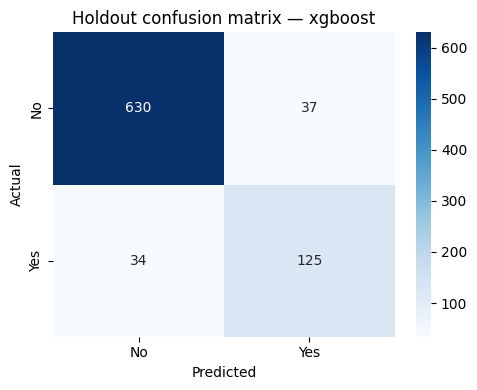

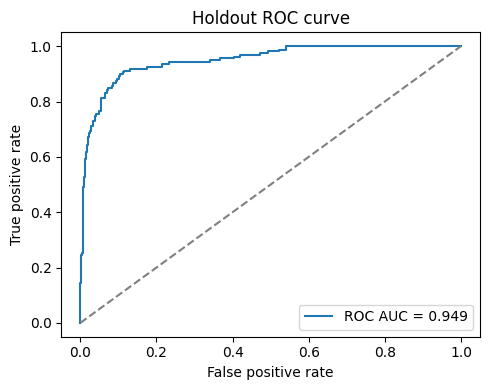

,feature,importance
0,numeric__Passport,0.1505
1,categorical__ProductPitched_Basic,0.1281
2,categorical__MaritalStatus_Single,0.0604
3,categorical__Occupation_Large Business,0.0586
4,numeric__CityTier,0.0571
5,categorical__ProductPitched_Standard,0.0363
6,numeric__PreferredPropertyStar,0.0354
7,categorical__ProductPitched_Deluxe,0.0351
8,categorical__ProductPitched_Super Deluxe,0.0346
9,categorical__TypeofContact_Company Invited,0.0327


Best model: xgboost. Selection rule: Highest five-fold cross-validated F2 on training data.
Business action: use scores to prioritize outreach and plan campaign capacity; validate with a prospective campaign.
Limitations: buyer class is 19.3%, the sample is modest, and historical interactions may encode selection bias. Monitor drift, calibration, and campaign outcomes before retraining.
Feature importances describe model associations after one-hot encoding; they are not causal effects.


In [27]:
import json, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score
from IPython.display import display
evaluation_path = PROJECT_ROOT / "model_building" / "artifacts" / "evaluation.json"
if evaluation_path.exists():
    evaluation = json.loads(evaluation_path.read_text(encoding="utf-8"))
    comparison = pd.DataFrame(evaluation["comparison"])
    columns = ["model", "cv_f2", "train_accuracy", "test_accuracy", "train_precision", "test_precision", "train_recall", "test_recall", "train_f1", "test_f1", "train_roc_auc", "test_roc_auc"]
    display(comparison[columns].round(3))
    cm = evaluation["test_confusion_matrix"]
    display(pd.DataFrame(cm, index=["Actual no", "Actual yes"], columns=["Predicted no", "Predicted yes"]))
    fig, ax = plt.subplots(figsize=(5, 4)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=ax)
    ax.set(title=f"Holdout confusion matrix — {evaluation['best_model']}", xlabel="Predicted", ylabel="Actual"); plt.tight_layout(); plt.show()
    fpr, tpr, _ = roc_curve(evaluation["y_test"], evaluation["y_probability"]); auc = roc_auc_score(evaluation["y_test"], evaluation["y_probability"])
    fig, ax = plt.subplots(figsize=(5, 4)); ax.plot(fpr, tpr, label=f"ROC AUC = {auc:.3f}"); ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(title="Holdout ROC curve", xlabel="False positive rate", ylabel="True positive rate"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
    importance = pd.DataFrame(evaluation["feature_importances"])
    if not importance.empty: display(importance.head(10).round(4))
    print(f"Best model: {evaluation['best_model']}. Selection rule: {evaluation['selection_rule']}.")
    print("Business action: use scores to prioritize outreach and plan campaign capacity; validate with a prospective campaign.")
    print("Limitations: buyer class is 19.3%, the sample is modest, and historical interactions may encode selection bias. Monitor drift, calibration, and campaign outcomes before retraining.")
    print("Feature importances describe model associations after one-hot encoding; they are not causal effects.")
else: print("Model artifacts are not present; execute the model-training cell first.")


- Streamlit Community Cloud (public app link and screenshot of the deployed Streamlit app)


[INSERT SCREENSHOT: public Streamlit Community Cloud app showing a prediction]


In [28]:
import json, os, requests, pandas as pd, joblib, sys
streamlit_app_url = os.getenv("STREAMLIT_APP_URL", "").strip()
app_ready = False
if streamlit_app_url:
    try:
        response = requests.get(streamlit_app_url, timeout=30)
        print({"streamlit_app_url": streamlit_app_url, "http_status": response.status_code, "content_type": response.headers.get("content-type"), "response_bytes": len(response.content)})
        app_ready = response.status_code == 200
    except requests.RequestException as exc:
        print({"streamlit_app_url": streamlit_app_url, "request_error": type(exc).__name__})
else:
    print("Streamlit app is not deployed yet. Deploy using STREAMLIT_CLOUD_DEPLOYMENT.md, then set STREAMLIT_APP_URL to its public URL.")
evaluation_path = PROJECT_ROOT / "model_building" / "artifacts" / "evaluation.json"
model_path = PROJECT_ROOT / "model_building" / "artifacts" / "tourism_model.joblib"
if evaluation_path.exists() and model_path.exists():
    sys.path.insert(0, str(PROJECT_ROOT / "deployment")); import app as tourism_app
    sample_payload = pd.read_csv(DATA_DIR / "processed" / "Xtest.csv").iloc[0].to_dict()
    local_model = joblib.load(model_path)
    result = tourism_app.predict_customer(sample_payload, model=local_model)
    print({"sample_request": sample_payload, "sample_prediction": result, "source": "saved model through the Streamlit app prediction function"})
    if app_ready: print("The public Streamlit app returned HTTP 200. The sample above exercises the same app prediction function with the saved model.")
else: print("Sample prediction is pending a trained model artifact.")


Streamlit app is not deployed yet. Deploy using STREAMLIT_CLOUD_DEPLOYMENT.md, then set STREAMLIT_APP_URL to its public URL.
{'sample_request': {'Age': 34.0, 'TypeofContact': 'Company Invited', 'CityTier': 1, 'DurationOfPitch': 9.0, 'Occupation': 'Salaried', 'Gender': 'Male', 'NumberOfPersonVisiting': 2, 'NumberOfFollowups': 4.0, 'ProductPitched': 'Basic', 'PreferredPropertyStar': 3.0, 'MaritalStatus': 'Married', 'NumberOfTrips': 4.0, 'Passport': 0, 'PitchSatisfactionScore': 1, 'OwnCar': 0, 'NumberOfChildrenVisiting': 0.0, 'Designation': 'Executive', 'MonthlyIncome': 17979.0}, 'sample_prediction': {'prediction': 'Will not purchase', 'class': 0, 'probability': 0.01115746796131134}, 'source': 'saved model through the Streamlit app prediction function'}


### Rubric self-audit and manual steps

The repository includes the notebook and HTML export, source dataset, preprocessing and training scripts, evaluation artifacts, Streamlit app, workflow, and documentation. Hugging Face dataset/model registration succeeded previously; the Docker Space job returned HTTP 402 because HF Docker Spaces require a paid plan. The free hosting route is Streamlit Community Cloud.

**Complete the free app deployment:** sign in to [Streamlit Community Cloud](https://share.streamlit.io/) with GitHub, create an app from `jhaashishmithilesh1005-jpg/tourism-wellness-mlops-project` on `main`, set the entry file to `tourism_project/deployment/app.py`, choose Python 3.12, leave Secrets empty, and deploy. Then add the app URL and a screenshot here and set `STREAMLIT_APP_URL` in the notebook before running the live app check.

**Pipeline:** the GitHub Actions workflow still requires the repository secret `HF_TOKEN` for Hub dataset/model uploads; do not paste it into the notebook or source files. The optional Hugging Face Docker Space job is skipped by default. A rubric item that specifically requires a public Hugging Face Docker Space cannot be completed on the free HF plan; Streamlit Community Cloud is the free alternative.

In [29]:
rubric_status = pd.DataFrame([
    {"section": "5.1 Data Registration", "status": "PASS in previous GitHub Actions run; public HF dataset exists"},
    {"section": "5.2 Data Preparation", "status": "PASS in previous GitHub Actions run"},
    {"section": "5.3 Model Training and MLflow", "status": "PASS in previous GitHub Actions run; public model exists"},
    {"section": "5.4 Model Deployment", "status": "Streamlit app is ready; first Community Cloud publish is manual"},
    {"section": "5.5 Hosting", "status": "Free Streamlit route; app URL and screenshot pending first deployment"},
    {"section": "5.6 GitHub Actions", "status": "Workflow updated; rerun after pushing; paid Docker job skipped by default"},
    {"section": "5.7 Output Evaluation", "status": "Local sample prediction present; live app check pending deployment"},
    {"section": "5.8 Notebook Quality", "status": "Notebook and HTML export updated for the free route"},
])
display(rubric_status)


<font size=6 color="navyblue">Power Ahead!</font>
___